# CNN Feature Visualization, Parameter Audit & Critical Analysis
### Deep Learning & Computer Vision — Practical Laboratory Assignment


## 1. Setup & Imports

In [1]:
import io, base64
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from PIL import Image, ImageDraw
from scipy.signal import correlate2d

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9})
SEED = 42
rng = np.random.default_rng(SEED)
print("NumPy", np.__version__, "| Matplotlib", matplotlib.__version__)

NumPy 2.4.6 | Matplotlib 3.10.0


## 2. Part I — Filter Pipeline Implementation & Visualization

### 2.1 Input image
The notebook ships with the reference architectural photograph (Figure 2 of the assignment sheet, embedded below as a base64 string so the notebook is fully self-contained). It has crisp horizontal and vertical structural edges, which is ideal for testing the kernels. If you prefer your own image, set `USE_OWN_IMAGE = True` in the cell after the next one and upload a file when prompted.

In [2]:
#@title Embedded reference image (Figure 2 from the assignment sheet) — double-click to show the base64 data
IMG_B64 = "..."

Input image shape (H, W): (286, 512) | min/max: 0.0 1.0 | mean: 0.365


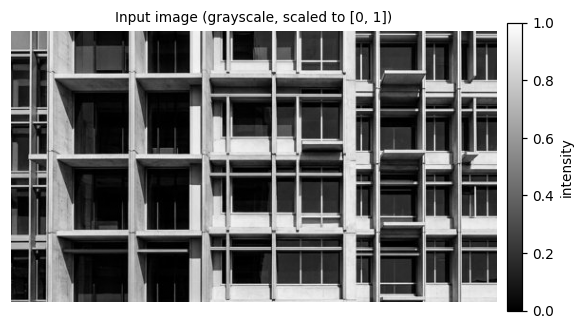

In [3]:
USE_OWN_IMAGE = False   # set True to upload your own picture in Colab

if USE_OWN_IMAGE:
    from google.colab import files
    up = files.upload()
    pil_img = Image.open(io.BytesIO(next(iter(up.values())))).convert("L")
    pil_img.thumbnail((512, 512))
else:
    pil_img = Image.open(io.BytesIO(base64.b64decode(IMG_B64))).convert("L")

# Grayscale, float32, scaled to [0, 1]
img = np.asarray(pil_img, dtype=np.float32) / 255.0
print("Input image shape (H, W):", img.shape, "| min/max:", img.min(), img.max(), "| mean: %.3f" % img.mean())

plt.figure(figsize=(6, 3.4))
plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.title("Input image (grayscale, scaled to [0, 1])")
plt.axis("off")
plt.colorbar(fraction=0.03, pad=0.02, label="intensity")
plt.show()

### 2.2 Five custom 3 × 3 kernels

| # | Kernel | Purpose |
|---|---|---|
| 1 | **Sobel-X** | Brief's "horizontal edge detector" (Sobel-X / Prewitt family). Measures the *horizontal intensity gradient* (right minus left) |
| 2 | **Sobel-Y** | Vertical-gradient detector (bottom minus top) |
| 3 | **Sharpen** | Boosts the centre pixel against its 4-neighbours (high-frequency boost) |
| 4 | **Box blur** | 3 × 3 mean filter (low-pass) |
| 5 | **Emboss** | Directional (diagonal) relief effect |

> **Naming note for the viva.** The brief labels Sobel-X as the *horizontal-edge* detector. Strictly, Sobel-X differentiates along the x-axis, so it responds strongest to **vertical structures** (pillars, mullions) where brightness changes from left to right. Likewise Sobel-Y responds to **horizontal structures** (slab edges, window sills). The verification cell below proves this on a synthetic step edge.

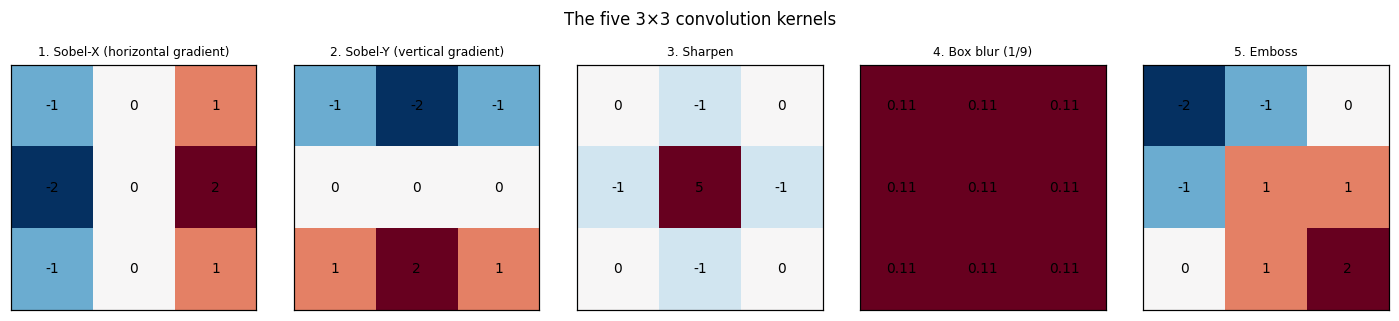

In [4]:
KERNELS = {
    "1. Sobel-X (horizontal gradient)": np.array([[-1, 0, 1],
                                                  [-2, 0, 2],
                                                  [-1, 0, 1]], dtype=np.float32),
    "2. Sobel-Y (vertical gradient)":   np.array([[-1, -2, -1],
                                                  [ 0,  0,  0],
                                                  [ 1,  2,  1]], dtype=np.float32),
    "3. Sharpen":                       np.array([[ 0, -1,  0],
                                                  [-1,  5, -1],
                                                  [ 0, -1,  0]], dtype=np.float32),
    "4. Box blur (1/9)":                np.ones((3, 3), dtype=np.float32) / 9.0,
    "5. Emboss":                        np.array([[-2, -1, 0],
                                                  [-1,  1, 1],
                                                  [ 0,  1, 2]], dtype=np.float32),
}

fig, axes = plt.subplots(1, 5, figsize=(13, 2.8))
for ax, (name, k) in zip(axes, KERNELS.items()):
    m = np.abs(k).max()
    ax.imshow(k, cmap="RdBu_r", vmin=-m, vmax=m)
    for (i, j), v in np.ndenumerate(k):
        ax.text(j, i, f"{v:.2f}".rstrip("0").rstrip("."), ha="center", va="center", fontsize=9)
    ax.set_title(name, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("The five 3×3 convolution kernels", y=1.02)
plt.tight_layout()
plt.show()

### 2.3 Layer operations (implemented from scratch with NumPy)

* **Convolution** — as in every deep-learning framework, this is *cross-correlation* (the kernel is not flipped). "Valid" padding, stride 1 → an `H × W` input becomes `(H−2) × (W−2)`.
* **ReLU** — `max(0, x)`.
* **Max / Average pooling** — 2 × 2 window, stride 2 (non-overlapping blocks; odd borders are cropped).

The convolution is verified against SciPy's `correlate2d` so the grid below can be trusted.

In [5]:
def conv2d_valid(x, k):
    """2-D cross-correlation, stride 1, no padding (what DL frameworks call 'convolution')."""
    windows = sliding_window_view(x, k.shape)           # (H-2, W-2, 3, 3)
    return (windows * k).sum(axis=(-1, -2))

def relu(a):
    return np.maximum(0.0, a)

def leaky_relu(a, alpha=0.1):
    return np.where(a > 0, a, alpha * a)

def sigmoid(a):
    return 1.0 / (1.0 + np.exp(-a))

def _blocks(a, p=2):
    h, w = (a.shape[0] // p) * p, (a.shape[1] // p) * p
    return a[:h, :w].reshape(h // p, p, w // p, p)

def max_pool(a, p=2):
    return _blocks(a, p).max(axis=(1, 3))

def avg_pool(a, p=2):
    return _blocks(a, p).mean(axis=(1, 3))

# ---- correctness check against SciPy ----
k_test = KERNELS["1. Sobel-X (horizontal gradient)"]
assert np.allclose(conv2d_valid(img, k_test), correlate2d(img, k_test, mode="valid"), atol=1e-5)
print("conv2d_valid matches scipy.signal.correlate2d  ✔")

# ---- tiny hand-checkable pooling example ----
demo = np.array([[1, 2, 5, 0],
                 [3, 4, 1, 1],
                 [0, 0, 2, 2],
                 [8, 0, 2, 2]], dtype=float)
print("\nDemo 4x4:\n", demo)
print("Max pool 2x2 :\n", max_pool(demo))
print("Avg pool 2x2 :\n", avg_pool(demo))

conv2d_valid matches scipy.signal.correlate2d  ✔

Demo 4x4:
 [[1. 2. 5. 0.]
 [3. 4. 1. 1.]
 [0. 0. 2. 2.]
 [8. 0. 2. 2.]]
Max pool 2x2 :
 [[4. 5.]
 [8. 2.]]
Avg pool 2x2 :
 [[2.5  1.75]
 [2.   2.  ]]


#### Sanity check — which structures does each Sobel kernel respond to?
A synthetic 6 × 6 image with a **vertical** step (dark left, bright right) and a **horizontal** step is pushed through both Sobel kernels. The sign of the response also shows *why* ReLU later removes half of the edges.

In [6]:
vstep = np.zeros((6, 6), dtype=np.float32); vstep[:, 3:] = 1.0        # dark | bright  (vertical edge)
hstep = np.zeros((6, 6), dtype=np.float32); hstep[3:, :] = 1.0        # dark over bright (horizontal edge)
sx, sy = KERNELS["1. Sobel-X (horizontal gradient)"], KERNELS["2. Sobel-Y (vertical gradient)"]

print("Vertical edge  (dark→bright going right)   Sobel-X output:\n", conv2d_valid(vstep, sx))
print("Same edge reversed (bright→dark going right) Sobel-X output:\n", conv2d_valid(vstep[:, ::-1].copy(), sx))
print("Horizontal edge (dark above, bright below)  Sobel-Y output:\n", conv2d_valid(hstep, sy))
print("Horizontal edge with Sobel-X (should be ~0):\n", conv2d_valid(hstep, sx))

Vertical edge  (dark→bright going right)   Sobel-X output:
 [[0. 4. 4. 0.]
 [0. 4. 4. 0.]
 [0. 4. 4. 0.]
 [0. 4. 4. 0.]]
Same edge reversed (bright→dark going right) Sobel-X output:
 [[ 0. -4. -4.  0.]
 [ 0. -4. -4.  0.]
 [ 0. -4. -4.  0.]
 [ 0. -4. -4.  0.]]
Horizontal edge (dark above, bright below)  Sobel-Y output:
 [[0. 0. 0. 0.]
 [4. 4. 4. 4.]
 [4. 4. 4. 4.]
 [0. 0. 0. 0.]]
Horizontal edge with Sobel-X (should be ~0):
 [[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


### 2.4 Sequential layer execution — Stages A → D
For every filter the four required tensors are recorded:

* **Stage A** raw convolution → **Stage B** post-ReLU → **Stage C** max-pool (2 × 2, s = 2) → **Stage D** average-pool (2 × 2, s = 2).

Both pooling stages are applied to the *post-ReLU* map, exactly as the brief requires.

In [7]:
results = {}
for name, k in KERNELS.items():
    A = conv2d_valid(img, k)      # Stage A: raw convolution
    B = relu(A)                   # Stage B: post-ReLU
    C = max_pool(B)               # Stage C: max pooling
    D = avg_pool(B)               # Stage D: average pooling
    results[name] = dict(A=A, B=B, C=C, D=D)

rows = [{"Filter": n,
         "A (conv)": r["A"].shape, "B (ReLU)": r["B"].shape,
         "C (max-pool)": r["C"].shape, "D (avg-pool)": r["D"].shape}
        for n, r in results.items()]
display(pd.DataFrame(rows).set_index("Filter"))

,A (conv),B (ReLU),C (max-pool),D (avg-pool)
Filter,,,,
1. Sobel-X (horizontal gradient),"(284, 510)","(284, 510)","(142, 255)","(142, 255)"
2. Sobel-Y (vertical gradient),"(284, 510)","(284, 510)","(142, 255)","(142, 255)"
3. Sharpen,"(284, 510)","(284, 510)","(142, 255)","(142, 255)"
4. Box blur (1/9),"(284, 510)","(284, 510)","(142, 255)","(142, 255)"
5. Emboss,"(284, 510)","(284, 510)","(142, 255)","(142, 255)"


### 2.5 Comparative visualization grid (5 rows × 4 columns)

**Intensity scaling (consistent within each row):**
* **Stage A** uses a *diverging* colormap centred on 0 (blue = negative, red = positive) so the negative values that ReLU will destroy are visible.
* **Stages B, C, D** share one grey scale per row, `0 … max(Stage B)`, so the effect of each operation can be compared pixel-for-pixel on the same brightness scale.
* Every panel has its own colorbar.

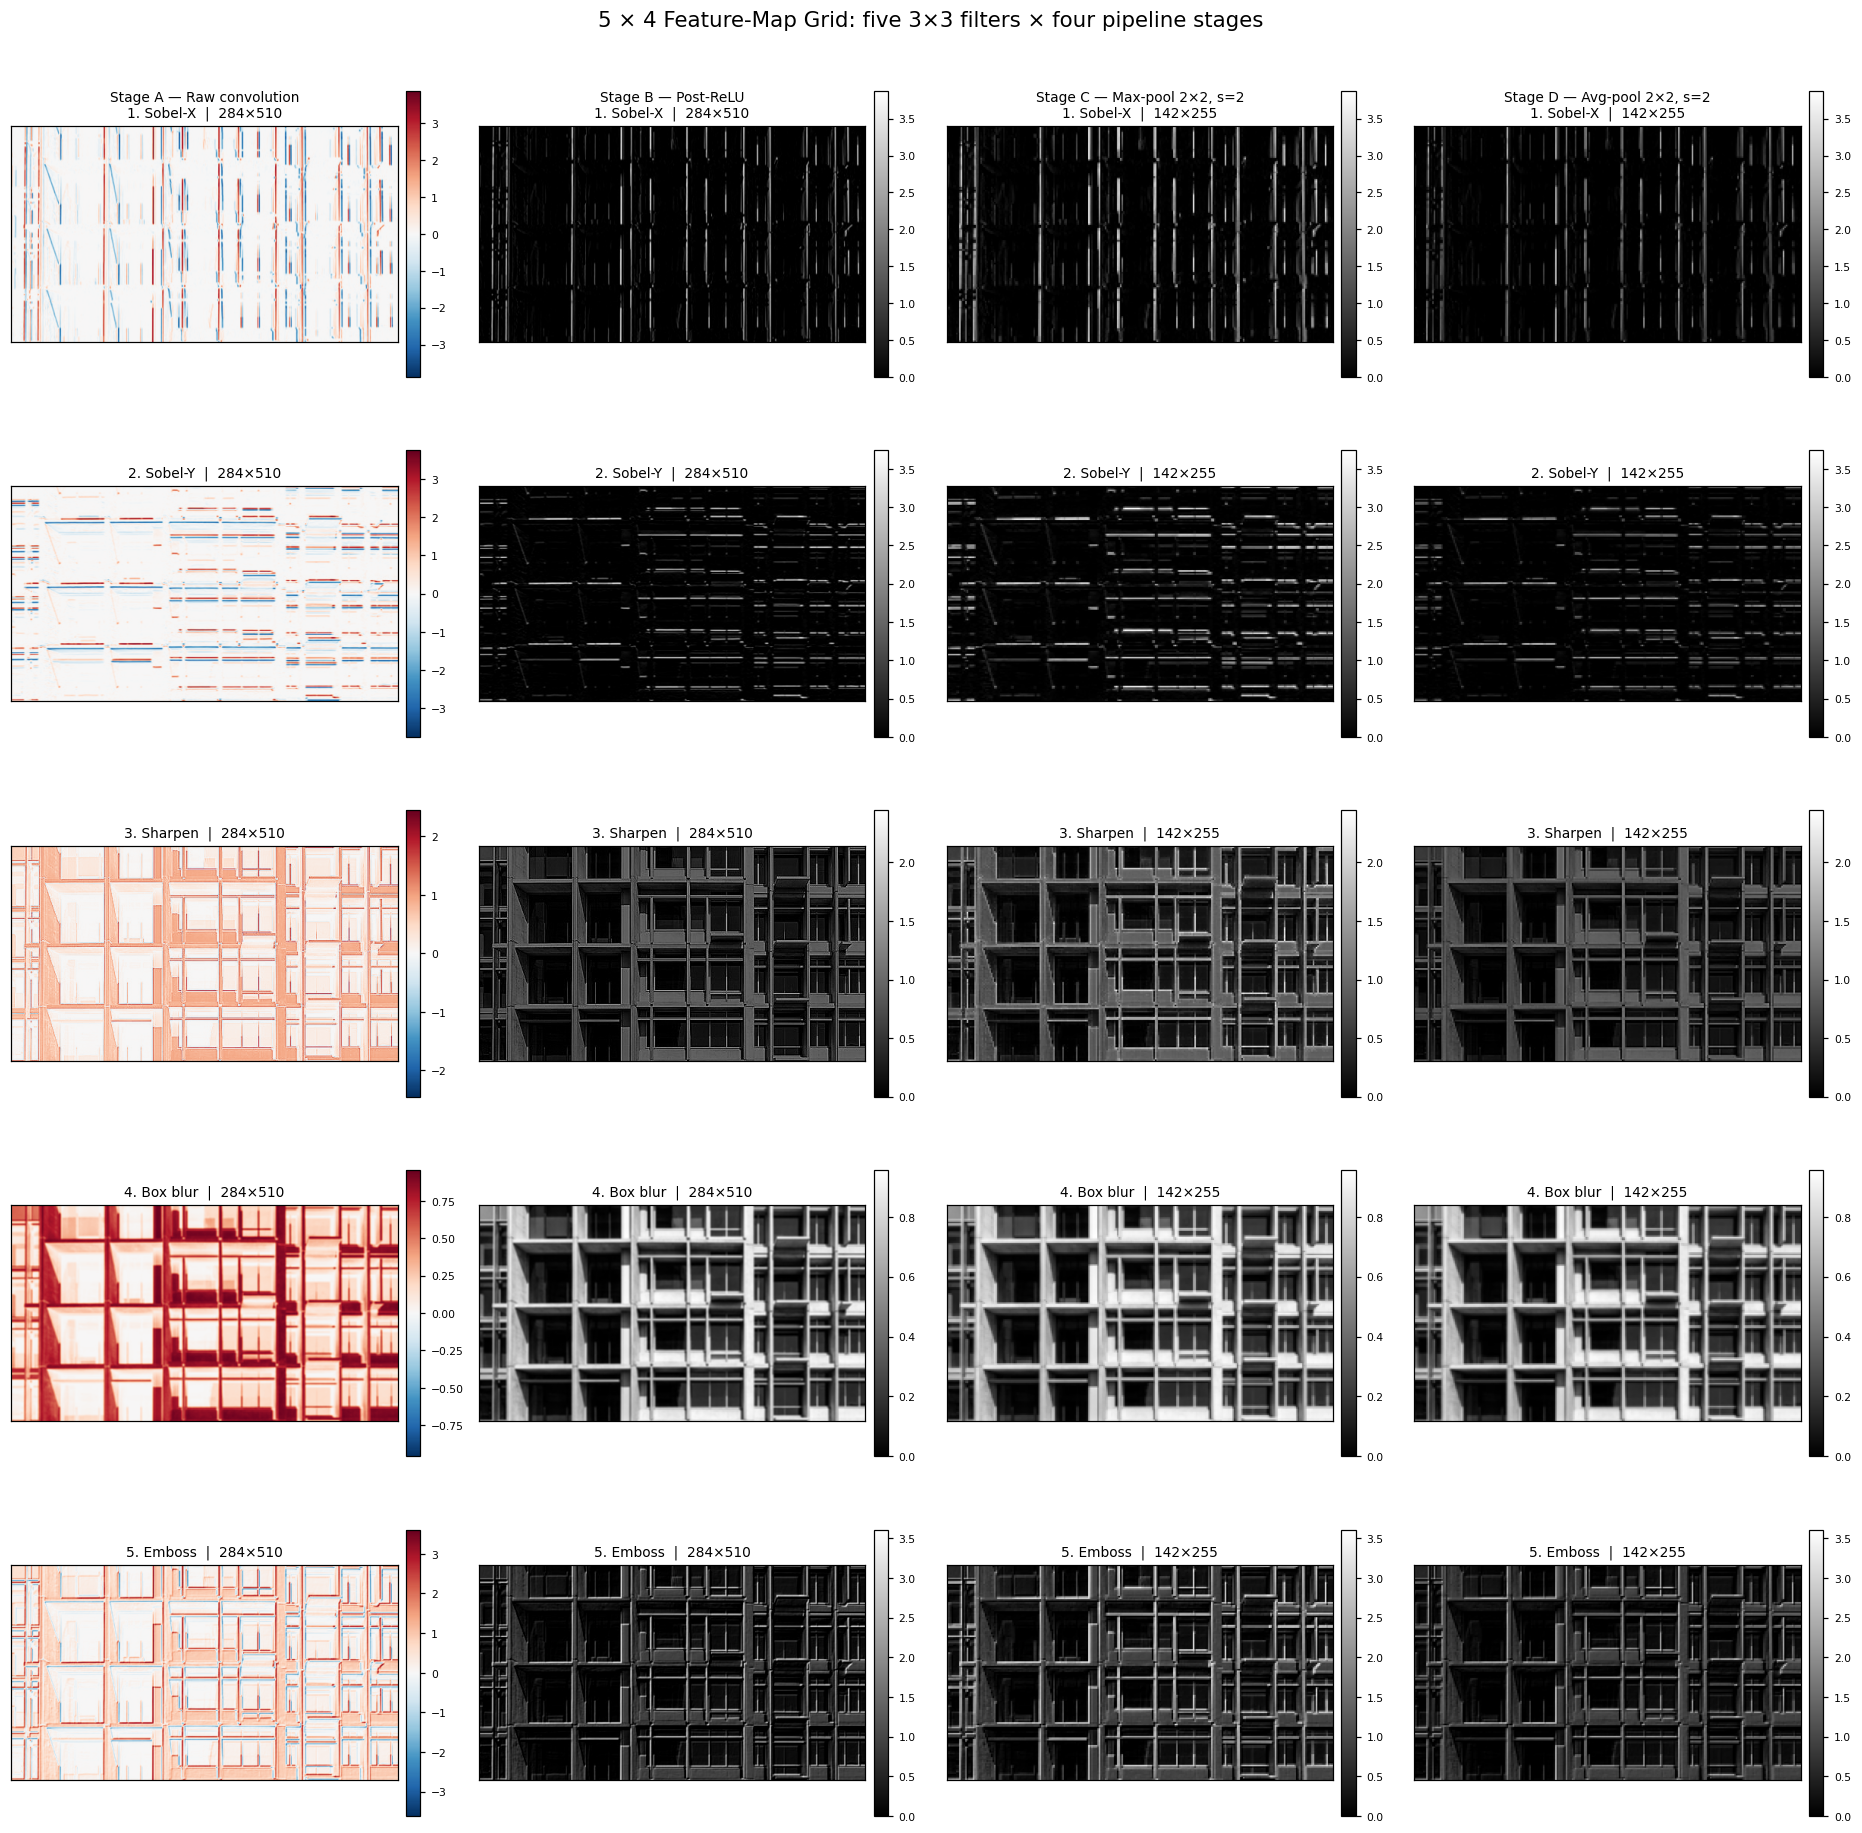

In [8]:
stage_titles = ["Stage A — Raw convolution", "Stage B — Post-ReLU",
                "Stage C — Max-pool 2×2, s=2", "Stage D — Avg-pool 2×2, s=2"]

fig, axes = plt.subplots(5, 4, figsize=(17, 17))
for r, (name, res) in enumerate(results.items()):
    lim = np.abs(res["A"]).max()            # symmetric range for Stage A
    top = res["B"].max()                    # shared 0..max range for B, C, D
    for c, key in enumerate("ABCD"):
        ax = axes[r, c]
        if key == "A":
            im = ax.imshow(res["A"], cmap="RdBu_r", vmin=-lim, vmax=lim)
        else:
            im = ax.imshow(res[key], cmap="gray", vmin=0, vmax=max(top, 1e-6))
        ax.set_xticks([]); ax.set_yticks([])
        h, w = res[key].shape
        ax.set_title((stage_titles[c] + "\n" if r == 0 else "") + f"{name.split('(')[0].strip()}  |  {h}×{w}", fontsize=9)
        cb = plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
        cb.ax.tick_params(labelsize=7)
plt.suptitle("5 × 4 Feature-Map Grid: five 3×3 filters × four pipeline stages", fontsize=14, y=0.995)
plt.tight_layout()
plt.savefig("cnn_5x4_grid.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.6 Quantitative evidence (used in the Part III answers)
These measurements are computed from the grid above so that every claim in the viva answers is backed by a number.

In [9]:
stats = []
for name, r in results.items():
    A, B, C, D = r["A"], r["B"], r["C"], r["D"]
    top = B.max()
    stats.append({
        "Filter": name,
        "A min": A.min(), "A max": A.max(),
        "% negative in A": 100 * (A < 0).mean(),
        "% zero in B (blackout)": 100 * (B == 0).mean(),
        "Max-pool peak (C)": C.max(), "Avg-pool peak (D)": D.max(),
        "Peak kept by Avg vs Max": D.max() / C.max(),
        "% pixels > 50% of peak, C": 100 * (C > 0.5 * top).mean(),
        "% pixels > 50% of peak, D": 100 * (D > 0.5 * top).mean(),
    })
stats_df = pd.DataFrame(stats).set_index("Filter").round(3)
display(stats_df)

,A min,A max,% negative in A,% zero in B (blackout),Max-pool peak (C),Avg-pool peak (D),Peak kept by Avg vs Max,"% pixels > 50% of peak, C","% pixels > 50% of peak, D"
Filter,,,,,,,,,
1. Sobel-X (horizontal gradient),-3.710,3.878,48.786,53.133,3.878,3.151,0.812,5.308,1.370
2. Sobel-Y (vertical gradient),-3.290,3.741,41.919,45.971,3.741,3.101,0.829,3.836,1.668
3. Sharpen,-1.361,2.447,18.134,18.583,2.447,1.634,0.668,12.367,0.729
4. Box blur (1/9),0.000,0.957,0.000,0.184,0.957,0.954,0.997,39.920,35.355
5. Emboss,-2.584,3.612,23.605,24.247,3.612,3.032,0.840,10.972,4.410


## 3. Part II — Architectural Comparison & Parameter Audit

Both models take a `32 × 32 × 3` RGB image, then:

`Conv1 (5 filters) → ReLU → Pool(2×2, s=2) → Conv2 (10 filters) → ReLU → Pool(2×2, s=2) → Global Average Pooling → Dense(10)`

| | Model A (Standard) | Model B (Large kernel) |
|---|---|---|
| Kernel size | 3 × 3 | 5 × 5 |
| Pooling | **Max** 2×2, stride 2 | **Average** 2×2, stride 2 |
| Padding | `same` | `same` |

Padding, pooling, ReLU and Global Average Pooling contain **no trainable parameters**, so only the convolution and Dense layers matter.

### 3.1 Hand calculation (done *before* calling `model.summary()`)

**Formulas**
* Conv layer: `(Kh × Kw × Cin + 1) × Cout` (the `+1` is the bias of each filter)
* Dense layer: `(inputs + 1) × outputs`

**Model A (3 × 3)**
* Conv1: `(3 × 3 × 3 + 1) × 5 = 28 × 5 = 140`
* Conv2: `(3 × 3 × 5 + 1) × 10 = 46 × 10 = 460`
* Global Average Pooling → 10 channels, **0** parameters
* Dense: `(10 + 1) × 10 = 110`
* **Total = 140 + 460 + 110 = 710**

**Model B (5 × 5)**
* Conv1: `(5 × 5 × 3 + 1) × 5 = 76 × 5 = 380`
* Conv2: `(5 × 5 × 5 + 1) × 10 = 126 × 10 = 1,260`
* Global Average Pooling: **0** parameters
* Dense: `(10 + 1) × 10 = 110`
* **Total = 380 + 1,260 + 110 = 1,750**

In [10]:
def conv_params(kh, kw, cin, cout):
    return (kh * kw * cin + 1) * cout

def dense_params(n_in, n_out):
    return (n_in + 1) * n_out

def audit(k):
    c1 = conv_params(k, k, 3, 5)
    c2 = conv_params(k, k, 5, 10)
    d  = dense_params(10, 10)         # GAP leaves 10 channels -> 10 classes
    return {"Conv1": c1, "Conv2": c2, "GAP": 0, "Dense": d, "Total": c1 + c2 + d}

manual = {"Model A": audit(3), "Model B": audit(5)}
display(pd.DataFrame(manual).T)

# Shape trace (padding='same'): confirms the Dense layer sees 10 features
def shape_trace():
    s = [("Input", (32, 32, 3)), ("Conv1", (32, 32, 5)), ("Pool1", (16, 16, 5)),
         ("Conv2", (16, 16, 10)), ("Pool2", (8, 8, 10)), ("GAP", (10,)), ("Dense", (10,))]
    for n, sh in s:
        print(f"{n:<6}{str(sh):>14}")
shape_trace()

,Conv1,Conv2,GAP,Dense,Total
Model A,140,460,0,110,710
Model B,380,1260,0,110,1750


Input    (32, 32, 3)
Conv1    (32, 32, 5)
Pool1    (16, 16, 5)
Conv2   (16, 16, 10)
Pool2     (8, 8, 10)
GAP            (10,)
Dense          (10,)


### 3.2 Framework models (Keras) and `model.summary()`
Run this cell in Colab (TensorFlow is pre-installed). The assertion compares the framework's parameter count with the hand calculation above.

In [11]:
try:
    import tensorflow as tf
    from tensorflow.keras import layers, models
    tf.keras.utils.set_random_seed(SEED)

    def build_model(kernel, pool_layer, name):
        return models.Sequential([
            layers.Input(shape=(32, 32, 3)),
            layers.Conv2D(5,  kernel, padding="same", activation="relu", name="conv1"),
            pool_layer(pool_size=(2, 2), strides=2, name="pool1"),
            layers.Conv2D(10, kernel, padding="same", activation="relu", name="conv2"),
            pool_layer(pool_size=(2, 2), strides=2, name="pool2"),
            layers.GlobalAveragePooling2D(name="gap"),
            layers.Dense(10, activation="softmax", name="dense_out"),
        ], name=name)

    model_a = build_model((3, 3), layers.MaxPooling2D,     "Model_A_3x3_MaxPool")
    model_b = build_model((5, 5), layers.AveragePooling2D, "Model_B_5x5_AvgPool")

    model_a.summary()
    model_b.summary()

    code_counts = {"Model A": model_a.count_params(), "Model B": model_b.count_params()}
    assert code_counts["Model A"] == manual["Model A"]["Total"]
    assert code_counts["Model B"] == manual["Model B"]["Total"]
    print("\nFramework counts match the hand calculation  ✔", code_counts)
except ImportError:
    code_counts = {"Model A": None, "Model B": None}
    print("TensorFlow is not installed in this environment - run this cell in Google Colab to see model.summary().")

Model: "Model_A_3x3_MaxPool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_out (Dense)               │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

Model: "Model_B_5x5_AvgPool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (AveragePooling2D)        │ (None, 16, 16, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 10)     │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (AveragePooling2D)        │ (None, 8, 8, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_out (Dense)               │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)


Framework counts match the hand calculation  ✔ {'Model A': 710, 'Model B': 1750}


### 3.3 Completed audit table

In [13]:
audit_table = pd.DataFrame([
    {"Model Configuration": "Model A (Standard)",
     "Conv Architecture": "Conv1: 5 filters, Conv2: 10 filters",
     "Kernel Size": "3 × 3", "Pooling Type": "Max Pooling (2×2, s=2)",
     "Manual Count": manual["Model A"]["Total"],
     "Code Output": code_counts["Model A"] if code_counts["Model A"] is not None else "run in Colab"},
    {"Model Configuration": "Model B (Large Kernel)",
     "Conv Architecture": "Conv1: 5 filters, Conv2: 10 filters",
     "Kernel Size": "5 × 5", "Pooling Type": "Avg Pooling (2×2, s=2)",
     "Manual Count": manual["Model B"]["Total"],
     "Code Output": code_counts["Model B"] if code_counts["Model B"] is not None else "run in Colab"},
]).set_index("Model Configuration")
display(audit_table)

,Conv Architecture,Kernel Size,Pooling Type,Manual Count,Code Output
Model Configuration,,,,,
Model A (Standard),"Conv1: 5 filters, Conv2: 10 filters",3 × 3,"Max Pooling (2×2, s=2)",710,710
Model B (Large Kernel),"Conv1: 5 filters, Conv2: 10 filters",5 × 5,"Avg Pooling (2×2, s=2)",1750,1750


---
## 4. Part III — Critical Thinking & Viva Defense Questions
Each answer below is preceded by a code cell that produces the evidence from **this notebook's own 5 × 4 grid** (Section 2.5). Row numbers refer to the grid rows: Row 1 = Sobel-X, Row 2 = Sobel-Y, Row 3 = Sharpen, Row 4 = Box blur, Row 5 = Emboss. Columns A–D are the four pipeline stages.

### Question 1 — The ReLU "Blackout" Effect & Activation Alternatives
**Evidence:** where the raw map (Stage A) is negative, and what Leaky ReLU (α = 0.1) and Sigmoid would do instead.

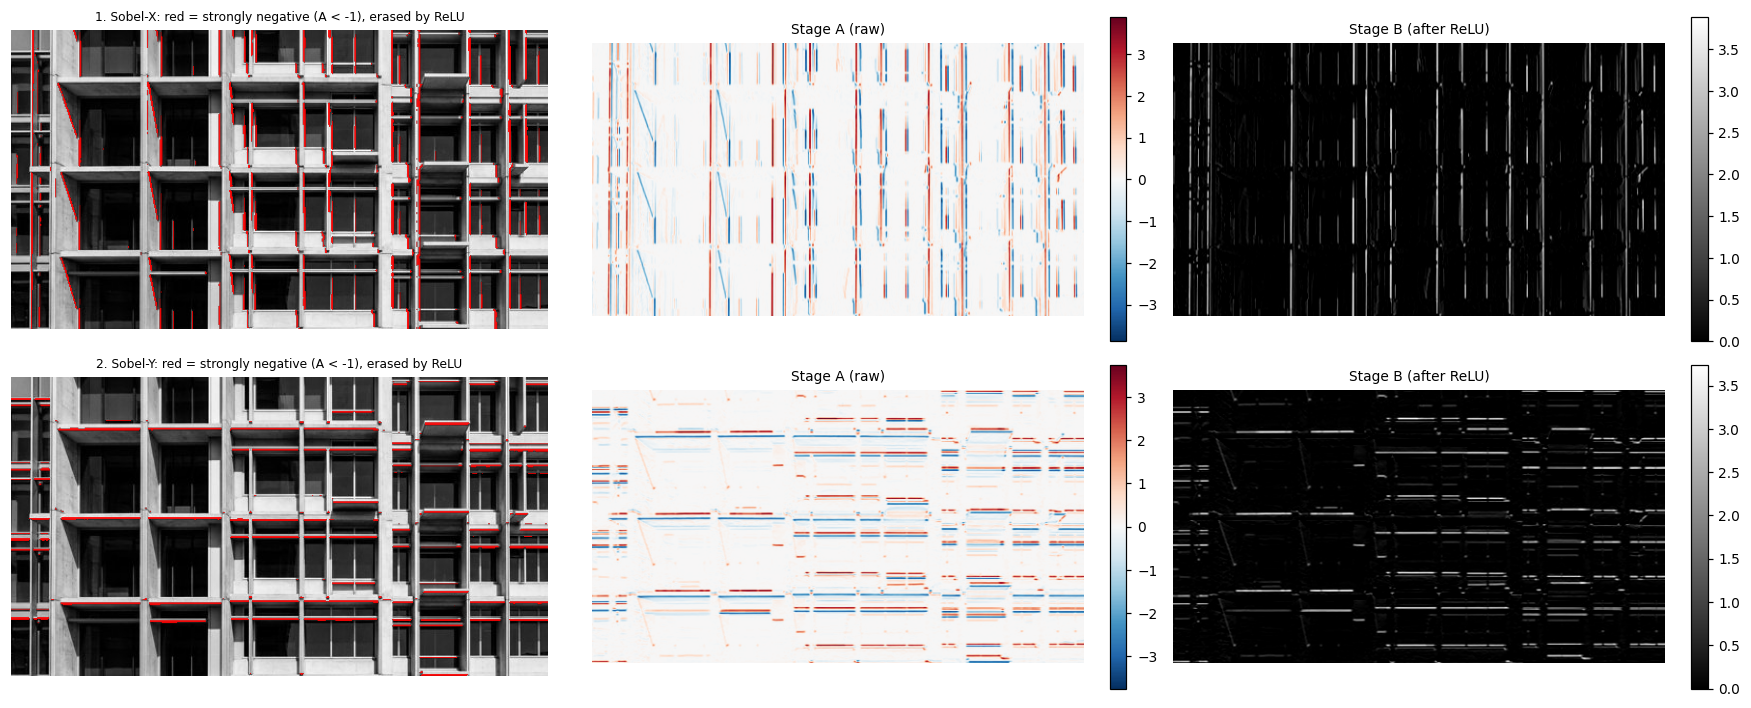

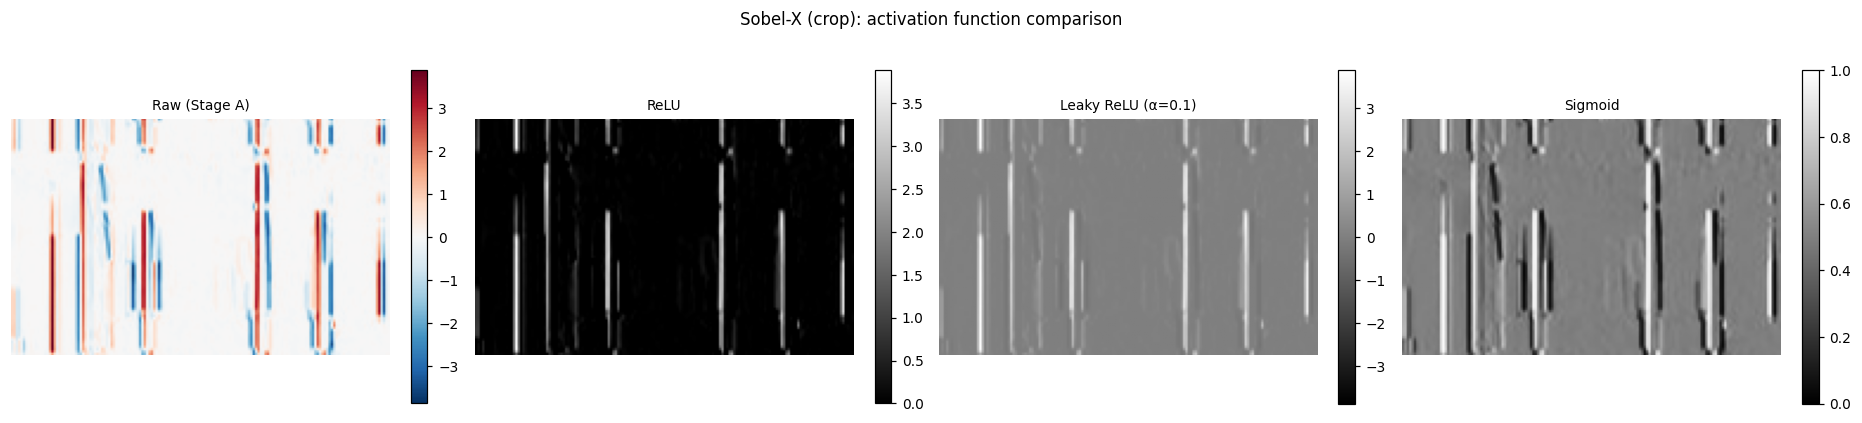

,min,max,% pixels exactly 0,% pixels < 0,value where input = 0
Activation,,,,,
Raw (Stage A),-3.710,3.878,4.347,48.786,0.0
ReLU,0.000,3.878,53.133,0.000,0.0
Leaky ReLU (α=0.1),-0.371,3.878,4.347,48.786,0.0
Sigmoid,0.024,0.980,0.000,0.000,0.5


1. Sobel-X:  48.8% negative +  4.3% exactly zero  ->  53.1% of the ReLU map is black (of which  5.6% of all pixels are STRONG negatives, A < -1)
2. Sobel-Y:  41.9% negative +  4.1% exactly zero  ->  46.0% of the ReLU map is black (of which  4.0% of all pixels are STRONG negatives, A < -1)


In [14]:
sx_name, sy_name = list(KERNELS)[0], list(KERNELS)[1]
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5))
for r, nm in enumerate([sx_name, sy_name]):
    A = results[nm]["A"]
    strong = A < -1.0                      # strong negative edge responses (clearly visible dark blue lines in A)
    axes[r, 0].imshow(img[1:-1, 1:-1], cmap="gray")
    ov = np.zeros(A.shape + (4,)); ov[strong] = [1, 0, 0, 0.9]
    axes[r, 0].imshow(ov)
    axes[r, 0].set_title(f"{nm.split('(')[0].strip()}: red = strongly negative (A < -1), erased by ReLU", fontsize=8)
    lim = np.abs(A).max()
    im = axes[r, 1].imshow(A, cmap="RdBu_r", vmin=-lim, vmax=lim); axes[r, 1].set_title("Stage A (raw)")
    plt.colorbar(im, ax=axes[r, 1], fraction=0.035)
    im = axes[r, 2].imshow(results[nm]["B"], cmap="gray", vmin=0, vmax=lim); axes[r, 2].set_title("Stage B (after ReLU)")
    plt.colorbar(im, ax=axes[r, 2], fraction=0.035)
    for ax in axes[r]: ax.axis("off")
plt.tight_layout(); plt.show()

# Activation functions on the Sobel-X raw map (zoomed crop, same scale for fair comparison)
A = results[sx_name]["A"]
crop = (slice(30, 130), slice(170, 330))
acts = {"Raw (Stage A)": A, "ReLU": relu(A), "Leaky ReLU (α=0.1)": leaky_relu(A, 0.1), "Sigmoid": sigmoid(A)}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, (n, M) in zip(axes, acts.items()):
    lim = max(abs(M[crop].min()), abs(M[crop].max()))
    im = ax.imshow(M[crop], cmap="RdBu_r" if n.startswith("Raw") else "gray",
                   vmin=-lim if n.startswith("Raw") else (0 if n != "Leaky ReLU (α=0.1)" else -lim),
                   vmax=lim if n != "Sigmoid" else 1)
    ax.set_title(n); ax.axis("off"); plt.colorbar(im, ax=ax, fraction=0.04)
plt.suptitle("Sobel-X (crop): activation function comparison", y=1.03)
plt.tight_layout(); plt.show()

q1 = []
for n, M in acts.items():
    q1.append({"Activation": n, "min": M.min(), "max": M.max(),
               "% pixels exactly 0": 100 * (M == 0).mean(),
               "% pixels < 0": 100 * (M < 0).mean(),
               "value where input = 0": float(dict(zip(acts, [0, 0, 0, 0.5]))[n])})
display(pd.DataFrame(q1).set_index("Activation").round(3))

for nm in (sx_name, sy_name):
    A = results[nm]["A"]
    print(f"{nm.split('(')[0].strip():8s}: {100*(A<0).mean():5.1f}% negative + {100*((A==0)).mean():4.1f}% exactly zero  "
          f"-> {100*(results[nm]['B']==0).mean():5.1f}% of the ReLU map is black "
          f"(of which {100*(A<-1).mean():4.1f}% of all pixels are STRONG negatives, A < -1)")

#### Answer 1

**Which regions went black?** (Grid Rows 1–2, Stage A → Stage B; overlay figure above.)

* **Row 1 — Sobel-X.** With this kernel the raw value is *(brightness to the right) − (brightness to the left)*, so its **sign encodes edge polarity**. Pixels that are bright on the left and dark on the right give a **negative** response. In the overlay these are the **right-hand edges of the bright concrete columns, mullions and slab ends** (equivalently the left-hand edge of each dark window opening). After ReLU, 53.1 % of the Stage-B map is black: 48.8 % of pixels were negative in Stage A and a further 4.3 % were exactly 0 (flat, uniform regions such as plain wall or the interior of dark windows, where left = right). Only the opposite polarity (dark → bright going right) survives as the thin bright vertical lines in Stage B.
* **Row 2 — Sobel-Y.** The raw value is *(brightness below) − (brightness above)*. Negative values occur where a bright area sits **above** a darker one: the **underside (bottom edges) of the bright horizontal slabs, sills and lintels**, i.e. where the slab meets the shadowed window below it. After ReLU 46.0 % of the map is black (41.9 % negative + 4.1 % exactly zero); only the top edges of the slabs remain.

**Why were those values negative?** Sobel kernels sum to zero (`−1 −2 −1 + 0 + 1 + 2 + 1 = 0`), so they output *differences*, not intensities. A difference can be positive or negative depending on the direction of the intensity step. The synthetic test in Section 2.3 shows it exactly: a dark→bright step gives `+4`, the same step reversed gives `−4`. ReLU, `max(0, x)`, treats the reversed polarity as "no feature" and writes 0 (black), so a single ReLU channel only "sees" **one half** of every edge pair.

**Leaky ReLU (α = 0.1) vs. Sigmoid** (activation comparison figure and table above):

| | ReLU | Leaky ReLU, α = 0.1 | Sigmoid |
|---|---|---|---|
| Formula | `max(0, x)` | `x` if `x>0`, else `0.1·x` | `1 / (1 + e^(−x))` |
| Sobel-X output range | 0 … 3.878 | −0.371 … 3.878 | 0.024 … 0.980 |
| Black pixels | 53.1 % | 4.3 % (only the exact zeros) | 0 % |
| Negative edges | erased | kept, shrunk 10× (faint dark lines) | kept as values < 0.5 |
| Flat background (x = 0) | 0 (black) | 0 (mid-grey on a signed scale) | **0.5 (mid-grey)** |
| Gradient for x < 0 | 0 (can die) | 0.1 (never zero) | σ(1−σ) ≤ 0.25, → 0 when \|x\| is large |

*Visually*, Leaky ReLU keeps the "blacked-out" regions as faint, scaled copies of the negative edges, so both polarities of every edge remain visible. Sigmoid turns the entire map grey: flat areas jump to 0.5, positive edges go towards white, negative edges towards black, and strong responses are squashed (3.88 → 0.98, −3.71 → 0.024). *Mathematically*, Leaky ReLU is still piece-wise linear and cheap, and it removes the dead-neuron problem; Sigmoid is smooth but dense (no sparsity), not zero-centred, saturating (vanishing gradients) and more expensive because of the exponential.

### Question 2 — Max Pooling vs. Average Pooling Information Retention
**Evidence (a):** Stage C vs Stage D for the Sharpen and edge rows, zoomed in on the same crop with the same brightness scale.
**Evidence (b):** a "dark ink on white paper" experiment.

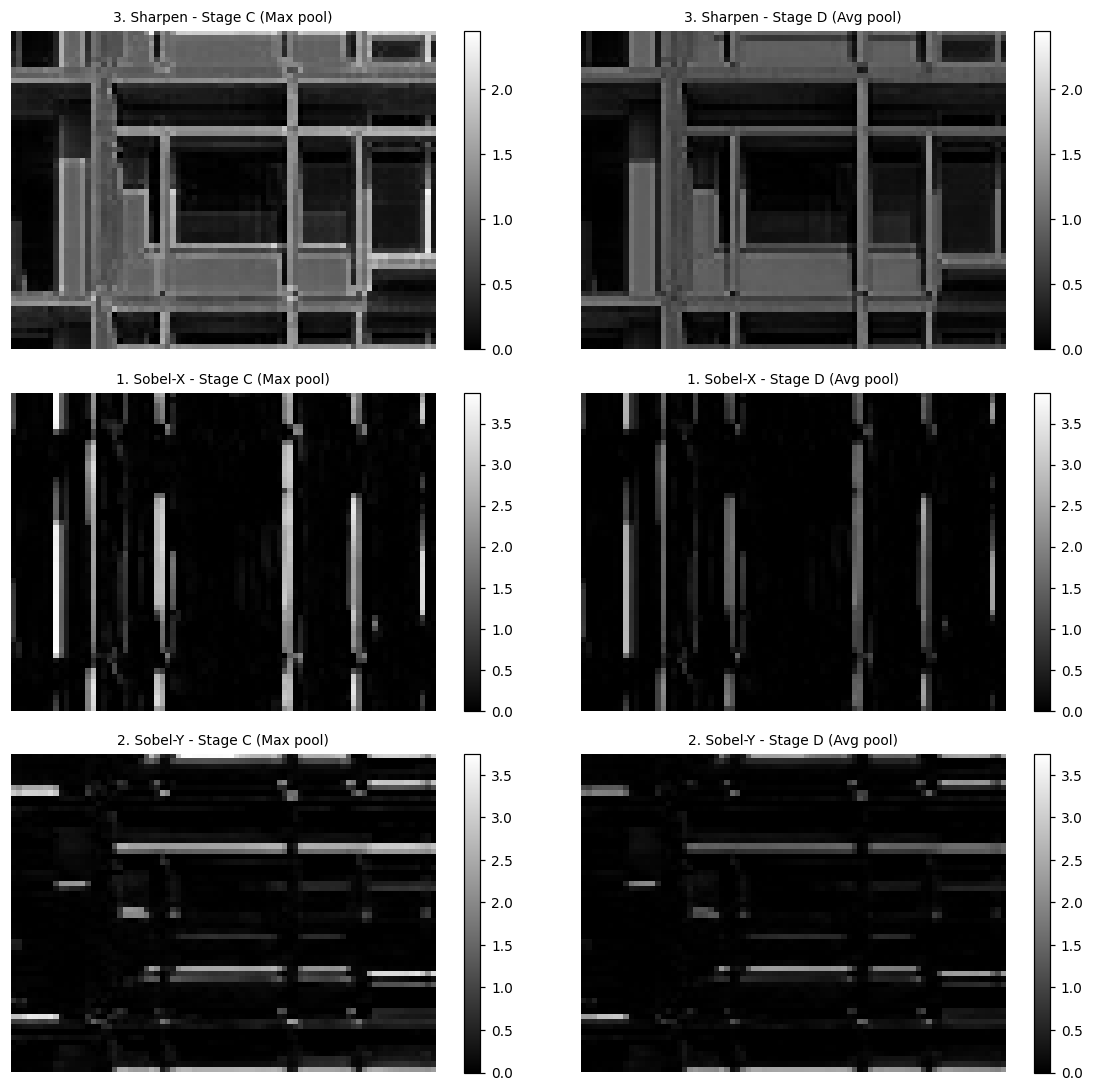

,Max-pool peak (C),Avg-pool peak (D),Peak kept by Avg vs Max,"% pixels > 50% of peak, C","% pixels > 50% of peak, D"
Filter,,,,,
1. Sobel-X (horizontal gradient),3.878,3.151,0.812,5.308,1.370
2. Sobel-Y (vertical gradient),3.741,3.101,0.829,3.836,1.668
3. Sharpen,2.447,1.634,0.668,12.367,0.729
4. Box blur (1/9),0.957,0.954,0.997,39.920,35.355
5. Emboss,3.612,3.032,0.840,10.972,4.410


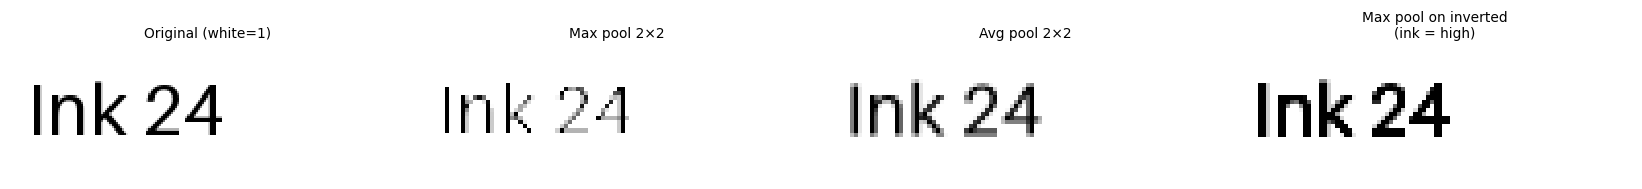

,Image,% 'ink' pixels (value < 0.5),darkest pixel
0,Original,5.241,0.0
1,Max pool,2.702,0.0
2,Avg pool,4.915,0.0
3,Max pool on inverted image,7.780,0.0


In [15]:
names = list(KERNELS)
crop_p = (slice(15, 75), slice(85, 165))        # crop in pooled coordinates
fig, axes = plt.subplots(3, 2, figsize=(11, 10))
for r, nm in enumerate([names[2], names[0], names[1]]):
    top = results[nm]["B"].max()
    for c, key in enumerate("CD"):
        im = axes[r, c].imshow(results[nm][key][crop_p], cmap="gray", vmin=0, vmax=top, interpolation="nearest")
        axes[r, c].set_title(f"{nm.split('(')[0].strip()} - Stage {key} ({'Max' if key=='C' else 'Avg'} pool)")
        axes[r, c].axis("off"); plt.colorbar(im, ax=axes[r, c], fraction=0.04)
plt.tight_layout(); plt.show()

# (a) numbers
display(stats_df[["Max-pool peak (C)", "Avg-pool peak (D)", "Peak kept by Avg vs Max",
                  "% pixels > 50% of peak, C", "% pixels > 50% of peak, D"]])

# (b) dark ink on a pure white page (white = 1.0 ~ pixel value 255)
from PIL import ImageFont
page = Image.new("L", (192, 64), 255)
try:
    font = ImageFont.load_default(size=34)
except TypeError:
    font = ImageFont.load_default()
ImageDraw.Draw(page).text((8, 10), "Ink 24", fill=0, font=font)
page = np.asarray(page, dtype=np.float32) / 255.0

mx, av = max_pool(page), avg_pool(page)
inv = 1.0 - page                                  # common fix: invert so ink is the bright signal
mx_inv = 1.0 - max_pool(inv)                      # max-pool on inverted image, then invert back

ink = lambda a: 100 * (a < 0.5).mean()
fig, axes = plt.subplots(1, 4, figsize=(15, 2.6))
for ax, (t, M) in zip(axes, [("Original (white=1)", page), ("Max pool 2×2", mx), ("Avg pool 2×2", av),
                             ("Max pool on inverted\n(ink = high)", mx_inv)]):
    ax.imshow(M, cmap="gray", vmin=0, vmax=1, interpolation="nearest"); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

display(pd.DataFrame({"Image": ["Original", "Max pool", "Avg pool", "Max pool on inverted image"],
                      "% 'ink' pixels (value < 0.5)": [ink(page), ink(mx), ink(av), ink(mx_inv)],
                      "darkest pixel": [page.min(), mx.min(), av.min(), mx_inv.min()]}).round(3))

#### Answer 2

**Features kept by Max Pooling but washed out by Average Pooling** (Grid Rows 1–3, Stage C vs Stage D, zoomed figure above):

| Filter | Peak of Stage C (max) | Peak of Stage D (avg) | Peak kept by avg | % pixels > 50 % of peak: max → avg |
|---|---|---|---|---|
| Sharpen | 2.447 | 1.634 | **66.8 %** | 12.4 % → **0.7 %** |
| Sobel-X | 3.878 | 3.151 | 81.2 % | 5.3 % → 1.4 % |
| Sobel-Y | 3.741 | 3.101 | 82.9 % | 3.8 % → 1.7 % |
| Emboss | 3.612 | 3.032 | 84.0 % | 11.0 % → 4.4 % |
| Box blur | 0.957 | 0.954 | 99.7 % | 39.9 % → 35.4 % |

* **Sharpen (Row 3):** the thin, high-contrast window-frame outlines and mullion lines are 1–2 px wide. Max pooling keeps their full brightness in Stage C; average pooling mixes them with the dark neighbours in the same 2 × 2 window, so in Stage D they turn into dim grey lines. Only 0.7 % of Stage-D pixels stay above half of the peak, compared with 12.4 % in Stage C.
* **Sobel-X / Sobel-Y (Rows 1–2):** single-pixel edge lines (narrow vertical mullions, thin horizontal sills) stay near full strength under max pooling. Under average pooling a one-pixel line that covers half of a 2 × 2 window is halved in intensity, and a diagonal or isolated pixel drops to a quarter.
* **Box blur (Row 4)** is the control experiment: it contains almost no high-frequency detail, so both pooling types give almost the same map (99.7 % of the peak kept). This confirms that the difference is a **high-frequency** effect.

**Dark ink on a pure white background (pixel values ≈ 255):** **Average pooling preserves the strokes better.** Max pooling returns the *brightest* pixel of each window, and the background is the brightest thing in the image, so a thin stroke disappears unless the whole 2 × 2 window is ink. In the ink experiment above the share of "ink" pixels fell from 5.24 % (original) to **2.70 %** after max pooling (strokes eroded), but stayed at **4.92 %** after average pooling (strokes kept, just blurred and slightly lighter). If the page is first *inverted* (ink becomes the bright signal), max pooling then keeps and even thickens the strokes (7.78 %), which is why OCR/MNIST-style pipelines normally use white-on-black text with max pooling.

### Question 3 — Parameter Explosion & Receptive Field Equivalence

In [16]:
a, b = manual["Model A"], manual["Model B"]
inc_total = 100 * (b["Total"] - a["Total"]) / a["Total"]
a_conv, b_conv = a["Conv1"] + a["Conv2"], b["Conv1"] + b["Conv2"]
inc_conv = 100 * (b_conv - a_conv) / a_conv
print(f"Total params : A = {a['Total']}, B = {b['Total']}  ->  increase = {b['Total']-a['Total']} params = {inc_total:.2f}%")
print(f"Conv-only    : A = {a_conv}, B = {b_conv}  ->  increase = {inc_conv:.2f}%")
print(f"Kernel-area ratio 25/9 = {25/9:.3f}  (explains why conv weights grow ~2.8x)")

# Receptive field of stacked 3x3 layers (stride 1): RF = 1 + 2*L
for L in range(1, 4):
    print(f"{L} stacked 3x3 layer(s) -> receptive field {1 + 2*L} x {1 + 2*L}")

# Savings, one 5x5 layer vs two stacked 3x3 layers with C input and C output channels
rows = []
for C in [3, 5, 10, 32, 64]:
    p5 = conv_params(5, 5, C, C)
    p33 = conv_params(3, 3, C, C) + conv_params(3, 3, C, C)
    rows.append({"C (in = out)": C, "one 5x5 layer": p5, "two 3x3 layers": p33,
                 "saved": p5 - p33, "saved %": round(100 * (p5 - p33) / p5, 2),
                 "weights-only saving 1-18/25": round(100 * (1 - 18 / 25), 1)})
display(pd.DataFrame(rows).set_index("C (in = out)"))

# What happens inside THIS network if each 5x5 layer is replaced by two 3x3 layers?
print("\nIn Model B itself:")
conv1_5 = conv_params(5, 5, 3, 5)
conv1_33 = conv_params(3, 3, 3, 5) + conv_params(3, 3, 5, 5)
conv2_5 = conv_params(5, 5, 5, 10)
conv2_33_inter10 = conv_params(3, 3, 5, 10) + conv_params(3, 3, 10, 10)     # intermediate width = 10
conv2_33_inter5  = conv_params(3, 3, 5, 5)  + conv_params(3, 3, 5, 10)      # intermediate width = 5
print(f"Conv1  5x5 = {conv1_5}  vs  3x3+3x3 (3->5->5)  = {conv1_33}   saving = {conv1_5 - conv1_33}")
print(f"Conv2  5x5 = {conv2_5} vs  3x3+3x3 (5->10->10) = {conv2_33_inter10} saving = {conv2_5 - conv2_33_inter10}")
print(f"Conv2  5x5 = {conv2_5} vs  3x3+3x3 (5->5->10)  = {conv2_33_inter5}  saving = {conv2_5 - conv2_33_inter5}")

Total params : A = 710, B = 1750  ->  increase = 1040 params = 146.48%
Conv-only    : A = 600, B = 1640  ->  increase = 173.33%
Kernel-area ratio 25/9 = 2.778  (explains why conv weights grow ~2.8x)
1 stacked 3x3 layer(s) -> receptive field 3 x 3
2 stacked 3x3 layer(s) -> receptive field 5 x 5
3 stacked 3x3 layer(s) -> receptive field 7 x 7


,one 5x5 layer,two 3x3 layers,saved,saved %,weights-only saving 1-18/25
C (in = out),,,,,
3,228,168,60,26.32,28.0
5,630,460,170,26.98,28.0
10,2510,1820,690,27.49,28.0
32,25632,18496,7136,27.84,28.0
64,102464,73856,28608,27.92,28.0



In Model B itself:
Conv1  5x5 = 380  vs  3x3+3x3 (3->5->5)  = 370   saving = 10
Conv2  5x5 = 1260 vs  3x3+3x3 (5->10->10) = 1370 saving = -110
Conv2  5x5 = 1260 vs  3x3+3x3 (5->5->10)  = 690  saving = 570


#### Answer 3

**Percentage increase (Model A → Model B).**

`Increase = (1750 − 710) / 710 × 100 = 1040 / 710 × 100 = 146.48 %`

The total grows by **146.48 %**. If only the convolution layers are compared (140 + 460 = 600 vs 380 + 1260 = 1640), the growth is 173.33 %, because the Dense layer (110 parameters) is identical in both models. The cause is the kernel area ratio `25 / 9 ≈ 2.78`: every filter has 2.78× more weights, so the "parameter explosion" gets worse as channel counts rise.

**Receptive-field equivalence.** The receptive field of `L` stacked stride-1 3 × 3 layers is `1 + 2L`, so **L = 2** stacked 3 × 3 layers give exactly the 5 × 5 field (see the printout above: 1 layer → 3×3, 2 layers → 5×5, 3 layers → 7×7).

**Parameters saved.** With `C` input and `C` output channels:

* one 5 × 5 layer: `25C² + C`
* two 3 × 3 layers: `2(9C² + C) = 18C² + 2C`
* saving: `7C² − C`, i.e. the weights shrink by `1 − 18/25 = 28 %`. For example `C = 5`: 630 vs 460, a saving of **170 parameters (27.0 %)**; `C = 64`: 102,464 vs 73,856 (27.9 %).

*Caveat for this specific Model B:* the exact saving depends on the width of the intermediate layer. Conv1 (3 → 5) saves 10 parameters (380 → 370). For Conv2 (5 → 10) a 5 → 5 → 10 stack saves 570 (1260 → 690), but a 5 → 10 → 10 stack would cost 110 *more*. The 28 % rule holds when the in/out widths are equal. Stacking also adds an extra ReLU (more non-linearity) and needs fewer multiplications for the same field.

### Question 4 — Operation Commutativity (Order Invariance)
**Numerical proof** on a 2 × 2 patch with negative numbers, followed by a randomized check on 100,000 patches and on the real feature maps of Part I.

In [17]:
def order1(P): return relu(P).max()                 # Conv -> ReLU -> MaxPool
def order2(P): return relu(np.array(P.max()))                          # Conv -> MaxPool -> ReLU

patches = {
    "mixed signs": np.array([[-3.0, 2.0], [-1.0, -5.0]]),
    "all negative": np.array([[-3.0, -2.0], [-1.0, -5.0]]),
    "all positive": np.array([[3.0, 2.0], [1.0, 5.0]]),
}
for n, P in patches.items():
    print(f"{n:13s} P = {P.tolist()}")
    print(f"   ReLU then Max : ReLU(P) = {relu(P).tolist()} -> max = {order1(P)}")
    print(f"   Max then ReLU : max(P) = {P.max()} -> ReLU = {float(order2(P))}")
    print("   identical:", np.isclose(order1(P), order2(P)))

# Randomized check
Prand = rng.normal(size=(100_000, 2, 2))
o1 = relu(Prand).max(axis=(1, 2))
o2 = relu(Prand.max(axis=(1, 2)))
print("\nMax-pool/ReLU order, 100,000 random patches: max |difference| =", np.abs(o1 - o2).max())

# Counter-example: average pooling does NOT commute with ReLU
P = patches["mixed signs"]
print("Average pooling: ReLU then Avg =", relu(P).mean(), "| Avg then ReLU =", float(relu(np.array(P.mean()))))

# Real feature maps from Part I
for nm, r in results.items():
    swapped = relu(max_pool(r["A"]))
    print(f"{nm.split('(')[0].strip():8s} identical to Stage C: {np.array_equal(swapped, r['C'])}")

# Cost: number of ReLU evaluations for the first Model-A conv output (32x32x5)
n_before_pool, n_after_pool = 32 * 32 * 5, 16 * 16 * 5
print(f"\nReLU evaluations on a 32x32x5 map: before pooling = {n_before_pool}, after pooling = {n_after_pool}  ({n_before_pool / n_after_pool:.0f}x fewer)")

mixed signs   P = [[-3.0, 2.0], [-1.0, -5.0]]
   ReLU then Max : ReLU(P) = [[0.0, 2.0], [0.0, 0.0]] -> max = 2.0
   Max then ReLU : max(P) = 2.0 -> ReLU = 2.0
   identical: True
all negative  P = [[-3.0, -2.0], [-1.0, -5.0]]
   ReLU then Max : ReLU(P) = [[0.0, 0.0], [0.0, 0.0]] -> max = 0.0
   Max then ReLU : max(P) = -1.0 -> ReLU = 0.0
   identical: True
all positive  P = [[3.0, 2.0], [1.0, 5.0]]
   ReLU then Max : ReLU(P) = [[3.0, 2.0], [1.0, 5.0]] -> max = 5.0
   Max then ReLU : max(P) = 5.0 -> ReLU = 5.0
   identical: True

Max-pool/ReLU order, 100,000 random patches: max |difference| = 0.0
Average pooling: ReLU then Avg = 0.5 | Avg then ReLU = 0.0
1. Sobel-X identical to Stage C: True
2. Sobel-Y identical to Stage C: True
3. Sharpen identical to Stage C: True
4. Box blur identical to Stage C: True
5. Emboss identical to Stage C: True

ReLU evaluations on a 32x32x5 map: before pooling = 5120, after pooling = 1280  (4x fewer)


#### Answer 4

**The result is identical** for Conv → ReLU → MaxPool and Conv → MaxPool → ReLU.

**Proof.** ReLU is monotonically non-decreasing, so it commutes with `max`:

`max(ReLU(x₁), …, ReLU(xₙ)) = max(max(0, x₁), …, max(0, xₙ)) = max(0, max(x₁, …, xₙ)) = ReLU(max(x₁, …, xₙ))`

**2 × 2 sample patch with negatives** `P = [[−3, 2], [−1, −5]]`

* ReLU → MaxPool: `ReLU(P) = [[0, 2], [0, 0]]`, `max = 2`
* MaxPool → ReLU: `max(P) = 2`, `ReLU(2) = 2`  → **same (2)**

**All-negative patch** `[[−3, −2], [−1, −5]]`: ReLU first gives all zeros, so the max is 0; max first gives −1, and `ReLU(−1) = 0` → **same (0)**.

This was also confirmed numerically: the difference over 100,000 random patches is exactly 0.0, and for all five real feature maps of Part I the swapped pipeline is `np.array_equal` to Stage C.

**Computational efficiency.** Pooling first reduces the tensor by 4× (2 × 2 window), so ReLU is evaluated on a quarter of the values: for the first block of Model A, **1,280 instead of 5,120 ReLU evaluations** (and less memory traffic). The result is the same, so MaxPool → ReLU is the cheaper order.

**Limits of the argument.** It only holds for *max* pooling with a *monotonic* activation (ReLU, Leaky ReLU with α > 0, sigmoid, tanh). It fails for **average pooling**: on the same patch, ReLU → Avg gives 0.5 but Avg → ReLU gives 0.0 (printed above). It also does not hold for non-monotonic activations such as GELU/Swish.

### Question 5 — Diagnosing Filter Redundancy (Debugging Scenario)
The two cells below reproduce the two classic failure modes on the real image from Part I: (1) *symmetric (constant) initialization* and (2) *dead ReLUs* from a destructive step.

In [18]:
def map_similarity(maps):
    flat = np.stack([m.ravel() for m in maps])
    flat = flat - flat.mean(axis=1, keepdims=True)
    norm = np.linalg.norm(flat, axis=1, keepdims=True) + 1e-12
    S = (flat / norm) @ (flat / norm).T
    return S[np.triu_indices(len(maps), 1)].mean()

# --- Cause 1: weight initialization ------------------------------------------------------
const_filters = [np.full((3, 3), 0.1, dtype=np.float32) for _ in range(5)]              # identical init
he_filters    = [(rng.normal(0, np.sqrt(2 / 9), (3, 3))).astype(np.float32) for _ in range(5)]  # He-normal, fan_in = 9

maps_const = [relu(conv2d_valid(img, f)) for f in const_filters]
maps_he    = [relu(conv2d_valid(img, f)) for f in he_filters]
print("Mean pairwise correlation of the 5 feature maps")
print(f"  identical/constant init : {map_similarity(maps_const):.3f}   (=1 -> identical -> filters can never diverge)")
print(f"  He-normal random init   : {map_similarity(maps_he):.3f}")

# --- Cause 2: dead ReLUs (too-high learning rate pushes bias very negative) -----------------
k = he_filters[0]
for bias in [0.0, -0.5, -2.0, -5.0]:
    z = conv2d_valid(img, k) + bias
    print(f"bias = {bias:5.1f} -> {100*(relu(z) > 0).mean():5.1f}% of positions still active, mean grad of ReLU = {(z > 0).mean():.3f}")

Mean pairwise correlation of the 5 feature maps
  identical/constant init : 1.000   (=1 -> identical -> filters can never diverge)
  He-normal random init   : 0.341
bias =   0.0 ->  92.4% of positions still active, mean grad of ReLU = 0.924
bias =  -0.5 ->  34.1% of positions still active, mean grad of ReLU = 0.341
bias =  -2.0 ->   0.0% of positions still active, mean grad of ReLU = 0.000
bias =  -5.0 ->   0.0% of positions still active, mean grad of ReLU = 0.000


#### Answer 5

**Root cause 1 — Symmetric / poor weight initialization.** If the filters start with the same (or all-zero) weights, they receive identical gradients in every step, so they stay identical forever and the "5 filters" behave like one. In the demonstration above, filters initialized to a constant give a mean pairwise map correlation of **1.000**, while He-normal random initialization gives **0.341**.
**Fix:** initialize with random, scaled weights, i.e. He (Kaiming) normal for ReLU networks (`kernel_initializer="he_normal"`; Glorot for tanh/sigmoid), never with constants or zeros. Standardize the inputs and optionally add BatchNorm so every filter starts in a useful range.

**Root cause 2 — Dead ReLUs caused by an overly large learning rate (or a large negative bias).** A big update step can push a filter's pre-activations negative for *every* input. ReLU then outputs 0 and its gradient is also 0, so the filter can never recover and its feature map is permanently blank or near-constant; the surviving maps end up looking alike. In the demonstration, a bias of −2 leaves **0.0 %** of positions active (versus 92.4 % at bias 0).
**Fix:** lower the learning rate (e.g. Adam at `1e-3` or below, with a warm-up or decay schedule and gradient clipping), start biases at 0 or a small positive value, and switch to Leaky ReLU / ELU (or add BatchNorm) so negative inputs keep a non-zero gradient.

**How to diagnose in practice:** print the pairwise correlation matrix of the filters/feature maps, the fraction of exactly-zero activations per channel, and the per-filter gradient norm; correlation ≈ 1 points to initialization, while a fraction of zeros ≈ 100 % points to dead ReLUs.

---
## 5. Summary of Key Results

| Item | Result |
|---|---|
| Input image | Figure 2 reference photograph, grayscale 286 × 512 |
| Feature-map sizes | Conv/ReLU 284 × 510 → both poolings 142 × 255 |
| ReLU blackout | Sobel-X 53.1 %, Sobel-Y 46.0 %, Sharpen 18.6 %, Blur 0.2 %, Emboss 24.2 % of pixels = 0 |
| Peak kept by average pooling vs max pooling | Sharpen 66.8 %, Sobel-X 81.2 %, Sobel-Y 82.9 %, Emboss 84.0 %, Blur 99.7 % |
| Model A parameters (manual) | 140 + 460 + 0 + 110 = **710** |
| Model B parameters (manual) | 380 + 1,260 + 0 + 110 = **1,750** |
| Increase A → B | **146.48 %** (conv layers only: 173.33 %) |
| Receptive-field equivalent of 5 × 5 | **2** stacked 3 × 3 layers (≈ 28 % fewer weights at equal channel width) |
| Conv → ReLU → MaxPool vs Conv → MaxPool → ReLU | **Identical** (proved and verified); second order is 4× cheaper for ReLU |
| Filter collapse | (1) symmetric initialization → He init; (2) dead ReLUs / high learning rate → lower LR, Leaky ReLU, BatchNorm |

### Submission checklist
- [ ] Fill in the student information table at the top.
- [ ] Run all cells in Colab (`Runtime → Run all`) so the Keras `model.summary()` output for Models A and B appears; take the screenshot for the audit table.
- [ ] Attach your hand-written step-by-step calculations (Section 3.1 is a typed version of them).
- [ ] Be ready to explain every grid panel and every formula in the viva.